<center><h1>Tang_Xiaoyun_HW7</h1></center>

Name: Noki Tang
<br>
Github Username: yuanjiujiu099-creator
<br>
USC ID: 3843547131

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

In [1]:
from pathlib import Path
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import balanced_accuracy_score, recall_score, silhouette_score

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from scipy.cluster.hierarchy import dendrogram

### (a) Download the Anuran Calls (MFCCs) Data Set

The data has 7,195 frog calls. Each row has 22 MFCC features and three labels: Family, Genus, and Species. I randomly use 70% of the rows for training and keep the rest for testing. All three labels use the same split.

In [2]:
csv_path = Path('Anuran Calls (MFCCs)/Frogs_MFCCs.csv')
zip_path = Path('Homework 7 Data.zip')
if zip_path.exists():
    with ZipFile(zip_path) as archive:
        with archive.open(csv_path.as_posix()) as csv_file:
            data = pd.read_csv(csv_file)
else:
    data_dir = Path('../data') if not csv_path.exists() else Path('.')
    data = pd.read_csv(data_dir / csv_path)
labels = ['Family', 'Genus', 'Species']

X = data.filter(regex=r'^MFCCs_').to_numpy()
Y = data[labels]                  # the 3 labels

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=42)
print('Training set size:', X_train.shape)
print('Test set size:', X_test.shape)
for lab in labels:
    print(lab, '- number of classes:', Y[lab].nunique())

Training set size: (5036, 22)
Test set size: (2159, 22)
Family - number of classes: 4
Genus - number of classes: 8
Species - number of classes: 10


### (b) Train a classifier for each label

#### (i) Research

Each call has $L = 3$ labels (Family, Genus, Species). Let $N$ be the number of calls, $y_{ij}$ the true value of label $j$ for call $i$, and $\hat{y}_{ij}$ the predicted value.

**Exact match (subset accuracy).** A call counts as correct only if **all three** labels are right. This is a very strict score.
$$\text{Exact Match} = \frac{1}{N}\sum_{i=1}^{N} I(\hat{y}_{i1}=y_{i1},\ \hat{y}_{i2}=y_{i2},\ \hat{y}_{i3}=y_{i3})$$

**Hamming distance.** For one call, it is the number of labels that are wrong (0, 1, 2 or 3).

**Hamming loss.** The fraction of all labels that are wrong (this is the formula in the lecture slides). It is the average Hamming distance divided by $L$. Smaller is better.
$$\text{Hamming Loss} = \frac{1}{NL}\sum_{i=1}^{N}\sum_{j=1}^{L} I(\hat{y}_{ij} \neq y_{ij})$$

**Hamming score.** People use two versions, so I report both. Bigger is better for both.
- **Label accuracy** = the fraction of labels that are right = $1 - \text{Hamming Loss}$.
- **Jaccard version**: treat the true labels $Y_i$ and the predicted labels $Z_i$ of a call as two sets and compute $\frac{1}{N}\sum_i \frac{|Y_i \cap Z_i|}{|Y_i \cup Z_i|}$. If $m$ of the 3 labels match, this is $\frac{m}{6-m}$. For example, if 2 of 3 labels match, label accuracy is 2/3 but the Jaccard score is 2/4.

Exact match gives no partial credit, while the Hamming measures do. So exact match will always be the lowest score.

In [3]:
def label_metrics(correct):
    matches = correct.sum(axis=1)
    n_labels = correct.shape[1]
    distance = (n_labels - matches).mean()
    loss = distance / n_labels
    label_accuracy = 1 - loss
    jaccard = (matches / (2 * n_labels - matches)).mean()
    return distance, loss, label_accuracy, jaccard


def evaluate(Y_true, Y_pred):
    correct = Y_true[labels].to_numpy() == Y_pred[labels].to_numpy()
    for j, lab in enumerate(labels):
        print(f'  {lab} accuracy: {correct[:, j].mean():.4f}')
    exact_match = correct.all(axis=1).mean()
    _, loss, label_accuracy, jaccard = label_metrics(correct)
    print(f'  Exact match: {exact_match:.4f}')
    print(f'  Hamming loss: {loss:.4f}')
    print(f'  Label accuracy: {label_accuracy:.4f}')
    print(f'  Hamming score (Jaccard): {jaccard:.4f}')
    return exact_match, loss, label_accuracy, jaccard

#### (ii) Train a SVM for each of the labels

I train a separate Gaussian SVM for each label. One-vs-rest trains one model for each class against the other classes and picks the class with the highest score. In scikit-learn, the Gaussian width σ is set using gamma = 1 / (2σ²). I first try a few settings on the training set to choose a range for cross-validation.

In [4]:
y = Y_train['Species']
for C in [0.01, 10000]:
    for sigma in [0.05, 0.25, 2.0, 10.0]:
        model = OneVsRestClassifier(SVC(kernel='rbf', C=C, gamma=1 / (2 * sigma**2)))
        model.fit(X_train, y)
        print(f'C = {C:<7}  sigma = {sigma:<5}  training accuracy = {model.score(X_train, y):.3f}')

C = 0.01     sigma = 0.05   training accuracy = 0.581
C = 0.01     sigma = 0.25   training accuracy = 0.907
C = 0.01     sigma = 2.0    training accuracy = 0.657
C = 0.01     sigma = 10.0   training accuracy = 0.532
C = 10000    sigma = 0.05   training accuracy = 1.000
C = 10000    sigma = 0.25   training accuracy = 1.000
C = 10000    sigma = 2.0    training accuracy = 1.000
C = 10000    sigma = 10.0   training accuracy = 0.987


At C = 0.01, three of the four widths gave less than 70% training accuracy. I search five values of C from 1 to 10,000 and eight widths for each version of the data. The raw features are already normalized. I try wider kernels for the standardized features and fit the scaler on the training part of each fold. I use 10-fold cross-validation to choose both settings for each label.

In [5]:
Cs = 10.0 ** np.arange(0, 5)
sigma_grid = {'raw': np.arange(0.25, 2.01, 0.25),
              'standardized': np.arange(1.0, 4.51, 0.5)}

rbf_results = {}
for version in ['raw', 'standardized']:
    print('=====', version, 'data =====')
    Y_pred = pd.DataFrame(index=Y_test.index, columns=labels)
    for lab in labels:
        if version == 'raw':
            scaler = 'passthrough'          # do nothing to the data
        else:
            scaler = StandardScaler()
        model = Pipeline([('scale', scaler),
                          ('svm', OneVsRestClassifier(SVC(kernel='rbf')))])
        params = {'svm__estimator__C': Cs,
                  'svm__estimator__gamma': 1 / (2 * sigma_grid[version] ** 2)}
        grid = GridSearchCV(model, params, cv=10, n_jobs=-1)
        grid.fit(X_train, Y_train[lab])

        best_C = grid.best_params_['svm__estimator__C']
        best_sigma = np.sqrt(1 / (2 * grid.best_params_['svm__estimator__gamma']))
        print(f'{lab}: best C = {best_C:g}, best sigma = {best_sigma:.2f}, CV accuracy = {grid.best_score_:.4f}')
        Y_pred[lab] = grid.predict(X_test)     # best model is refit on all training data
    print('Test set results:')
    rbf_results[version] = evaluate(Y_test, Y_pred)

===== raw data =====
Family: best C = 10, best sigma = 0.50, CV accuracy = 0.9934
Genus: best C = 10, best sigma = 0.50, CV accuracy = 0.9911
Species: best C = 10, best sigma = 0.50, CV accuracy = 0.9905
Test set results:
  Family accuracy: 0.9944
  Genus accuracy: 0.9907
  Species accuracy: 0.9912
  Exact match: 0.9889
  Hamming loss: 0.0079
  Label accuracy: 0.9921
  Hamming score (Jaccard): 0.9911
===== standardized data =====
Family: best C = 100, best sigma = 3.00, CV accuracy = 0.9929
Genus: best C = 10, best sigma = 3.00, CV accuracy = 0.9911
Species: best C = 100, best sigma = 3.50, CV accuracy = 0.9909
Test set results:
  Family accuracy: 0.9940
  Genus accuracy: 0.9880
  Species accuracy: 0.9889
  Exact match: 0.9866
  Hamming loss: 0.0097
  Label accuracy: 0.9903
  Hamming score (Jaccard): 0.9891


The raw and standardized Gaussian SVMs get similar test results. The raw model gets a slightly higher exact match and a slightly lower Hamming loss.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

I use a linear SVM with an L1 penalty. This penalty can set some feature weights to zero. I standardize the features inside the pipeline and use 10-fold cross-validation to pick C. LinearSVC uses one-vs-rest for each label, and a larger C means a weaker penalty.

In [6]:
Cs_l1 = np.logspace(-3, 2, 11)
plain_pred = pd.DataFrame(index=Y_test.index, columns=labels)
for lab in labels:
    model = Pipeline([('scale', StandardScaler()),
                      ('svm', LinearSVC(penalty='l1', dual=False, max_iter=100000, random_state=42))])
    grid = GridSearchCV(model, {'svm__C': Cs_l1}, cv=10, n_jobs=-1)
    grid.fit(X_train, Y_train[lab])
    print(f"{lab}: best C = {grid.best_params_['svm__C']:.4g}, CV accuracy = {grid.best_score_:.4f}")
    plain_pred[lab] = grid.predict(X_test)
print('Test set results:')
l1_results = evaluate(Y_test, plain_pred)

Family: best C = 1, CV accuracy = 0.9406
Genus: best C = 10, CV accuracy = 0.9527
Species: best C = 10, CV accuracy = 0.9603
Test set results:
  Family accuracy: 0.9287
  Genus accuracy: 0.9416
  Species accuracy: 0.9592
  Exact match: 0.9129
  Hamming loss: 0.0568
  Label accuracy: 0.9432
  Hamming score (Jaccard): 0.9344


The linear L1 SVM gets a lower exact match and a higher Hamming loss than either Gaussian SVM on the test set.

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

Some classes have far fewer calls than others. SMOTE adds examples between nearby points in the same class to give the smaller classes more training examples. I run it inside the pipeline after scaling, so it only sees the training part of each fold. The validation and test sets keep their original calls.

In [7]:
smote_pred = pd.DataFrame(index=Y_test.index, columns=labels)
for lab in labels:
    model = ImbPipeline([('scale', StandardScaler()),
                         ('smote', SMOTE(random_state=42)),
                         ('svm', LinearSVC(penalty='l1', dual=False, max_iter=100000, random_state=42))])
    grid = GridSearchCV(model, {'svm__C': Cs_l1}, cv=10, n_jobs=-1)
    grid.fit(X_train, Y_train[lab])
    print(f"{lab}: best C = {grid.best_params_['svm__C']:.4g}, CV accuracy = {grid.best_score_:.4f}")
    smote_pred[lab] = grid.predict(X_test)
print('Test set results:')
smote_results = evaluate(Y_test, smote_pred)

Family: best C = 3.162, CV accuracy = 0.9212
Genus: best C = 3.162, CV accuracy = 0.9124
Species: best C = 0.3162, CV accuracy = 0.9573
Test set results:
  Family accuracy: 0.9092
  Genus accuracy: 0.9018
  Species accuracy: 0.9579
  Exact match: 0.8527
  Hamming loss: 0.0770
  Label accuracy: 0.9230
  Hamming score (Jaccard): 0.9037


I also check balanced accuracy, which averages recall across classes and gives each class the same weight. I use the test predictions from the models selected above.

In [8]:
for lab in labels:
    before = balanced_accuracy_score(Y_test[lab], plain_pred[lab])
    after = balanced_accuracy_score(Y_test[lab], smote_pred[lab])
    print(f'{lab}: without SMOTE = {before:.4f}, with SMOTE = {after:.4f}')

Family: without SMOTE = 0.6904, with SMOTE = 0.9131
Genus: without SMOTE = 0.7690, with SMOTE = 0.9154
Species: without SMOTE = 0.8948, with SMOTE = 0.9281


To see where the change comes from, I look at the recall of each Family class (the fraction of calls of that class that the model finds).

In [9]:
families = sorted(Y['Family'].unique())
recall_table = pd.DataFrame({
    'size in test set': Y_test['Family'].value_counts()[families].values,
    'recall without SMOTE': recall_score(Y_test['Family'], plain_pred['Family'], labels=families, average=None),
    'recall with SMOTE': recall_score(Y_test['Family'], smote_pred['Family'], labels=families, average=None)},
    index=families)
recall_table.round(3)

,size in test set,recall without SMOTE,recall with SMOTE
Bufonidae,27,0.000,0.889
Dendrobatidae,162,0.895,0.975
Hylidae,623,0.904,0.867
Leptodactylidae,1347,0.963,0.921


In [10]:
summary = pd.DataFrame([rbf_results['raw'], rbf_results['standardized'], l1_results, smote_results],
                       columns=['Exact match', 'Hamming loss', 'Label accuracy',
                                'Hamming score (Jaccard)'],
                       index=['Gaussian SVM (raw)', 'Gaussian SVM (standardized)',
                              'L1 linear SVM', 'L1 linear SVM + SMOTE'])
summary.round(4)

,Exact match,Hamming loss,Label accuracy,Hamming score (Jaccard)
Gaussian SVM (raw),0.9889,0.0079,0.9921,0.9911
Gaussian SVM (standardized),0.9866,0.0097,0.9903,0.9891
L1 linear SVM,0.9129,0.0568,0.9432,0.9344
L1 linear SVM + SMOTE,0.8527,0.0770,0.9230,0.9037


**Conclusions about the classifiers.**
- **The Gaussian kernel SVM is the best.** On raw data it gets about 99% accuracy on every label, an exact match of 0.9889 and a Hamming loss of 0.0079. Raw and standardized data give almost the same results, because the features were already normalized. The raw version is a little better.
- **The L1-penalized linear SVM is worse** (exact match 0.9129, Hamming loss 0.0568). A linear SVM can only draw flat boundaries between classes, but the Gaussian kernel can draw curved ones, and this data seems to need curved boundaries. The good side of the L1 penalty is that the model is simpler and can set some feature weights to 0.
- **SMOTE lowers the overall scores but helps the small classes.** Exact match drops to 0.8527 and Hamming loss rises to 0.0770. But balanced accuracy goes up for every label (Family: 0.69 → 0.91, Genus: 0.77 → 0.92, Species: 0.89 → 0.93). The recall table shows why: without SMOTE, the model almost never finds the tiny *Bufonidae* class, because it can get high accuracy by focusing on the big classes. With SMOTE, the small classes get as many training examples as the big ones, so the model finds them much better, but it makes a few more mistakes on the big classes. The big classes have most of the test calls, so the overall accuracy drops.
- **Exact match is always the lowest score**, because one wrong label out of three is enough to count the whole call as wrong.
- **Overall:** if we only care about total accuracy, the Gaussian SVM is the best choice. If the small classes matter, a method for class imbalance like SMOTE is a good idea, at least for the linear SVM.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

**Monte-Carlo simulation.** I repeat parts (a) to (c) 50 times with random seeds 0 to 49, so k-means starts from different random centers each time. I use all 7,195 calls in each run (no train/test split) and report the mean and standard deviation of the 50 results. Below I first show the details of run 1, and then run all 50.

### (a) Use k-means clustering

To choose $k$ I use the **average silhouette** from the slides. For each point, $a_i$ is the average distance to the other points in its own cluster and $b_i$ is the smallest average distance to the points of another cluster. The silhouette is
$$s_i = \frac{b_i - a_i}{\max(a_i, b_i)},$$
which is between -1 and 1. A value close to 1 means the point fits its own cluster much better than the next cluster. I pick the $k$ with the **largest average silhouette**.

The silhouette needs at least 2 clusters ($b_i$ does not exist when $k = 1$), so I search $k \in \{2, 3, \ldots, 50\}$. For each $k$, k-means uses 10 random starts and keeps the best one, as the textbook suggests, because one start can get stuck in a bad local solution.

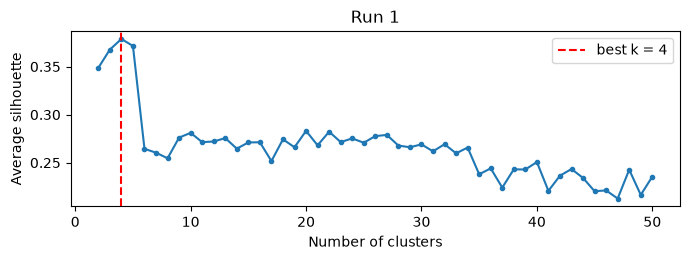

Chosen k in run 1: 4


In [11]:
X_all = X
Y_all = Y
k_values = range(2, 51)

def choose_k(seed):
    # run k-means for every k and keep the k with the largest average silhouette
    best_k, best_ids, best_score = None, None, -np.inf
    scores = []
    for k in k_values:
        model = KMeans(n_clusters=k, n_init=10, random_state=seed)
        ids = model.fit_predict(X_all)
        score = silhouette_score(X_all, ids)
        scores.append(score)
        if score > best_score:
            best_k, best_ids, best_score = k, ids, score
    return best_k, best_ids, scores

best_k, cluster_ids, sil_scores = choose_k(seed=0)
plt.figure(figsize=(7, 2.7))
plt.plot(list(k_values), sil_scores, marker='o', markersize=3)
plt.axvline(best_k, color='red', linestyle='--', label=f'best k = {best_k}')
plt.xlabel('Number of clusters')
plt.ylabel('Average silhouette')
plt.title('Run 1')
plt.legend()
plt.tight_layout()
plt.show()
print('Chosen k in run 1:', best_k)

### (b) Determine which family is the majority

For each cluster, I find the most common Family, Genus, and Species separately. The three values form the label triplet for that cluster.

In [12]:
def majority_labels(cluster_ids):
    # for each cluster, find the most common Family, Genus and Species
    table = Y_all.copy()
    table['cluster'] = cluster_ids
    majority = table.groupby('cluster')[labels].agg(
        lambda col: col.value_counts().index[0]
    )
    majority['size'] = table['cluster'].value_counts().sort_index()
    return majority

majority = majority_labels(cluster_ids)
majority

,Family,Genus,Species,size
cluster,,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,3568
1,Hylidae,Hypsiboas,HypsiboasCordobae,1982
2,Dendrobatidae,Ameerega,Ameeregatrivittata,1031
3,Hylidae,Hypsiboas,HypsiboasCinerascens,614


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

I give each call its cluster’s majority label triplet. I compare it with the true triplet and use the same four measures as above: average Hamming distance, Hamming loss, label accuracy, and the Jaccard version of Hamming score.

In [13]:
def hamming_metrics(cluster_ids, majority):
    predicted = majority.loc[cluster_ids, labels].to_numpy()
    correct = Y_all[labels].to_numpy() == predicted
    return label_metrics(correct)


distance, loss, accuracy, jaccard = hamming_metrics(cluster_ids, majority)
print(f'Run 1 Hamming distance: {distance:.4f}')
print(f'Hamming loss: {loss:.4f} | Label accuracy: {accuracy:.4f}')
print(f'Hamming score (Jaccard): {jaccard:.4f}')

Run 1 Hamming distance: 0.6673
Hamming loss: 0.2224 | Label accuracy: 0.7776
Hamming score (Jaccard): 0.7703


The first run is included once in the 50-run summary below.

In [14]:
results = [(best_k, distance, loss, accuracy, jaccard)]
for seed in range(1, 50):
    k, ids, _ = choose_k(seed)
    scores = hamming_metrics(ids, majority_labels(ids))
    results.append((k, *scores))

metrics = ['Hamming distance', 'Hamming loss', 'Label accuracy',
           'Hamming score (Jaccard)']
runs = pd.DataFrame(results, columns=['k'] + metrics)
print('Number of runs for each k:', runs['k'].value_counts().to_dict())
runs[metrics].agg(['mean', 'std']).round(4)

Number of runs for each k: {4: 50}


,Hamming distance,Hamming loss,Label accuracy,Hamming score (Jaccard)
mean,0.6719,0.2240,0.7760,0.7677
std,0.0170,0.0057,0.0057,0.0094


**Results of the 50 runs.**
- The silhouette method chose **k = 4 in all 50 runs**. This makes sense, because the data has exactly 4 families.
- In run 1, the majority triplets of the 4 clusters are (Leptodactylidae, Adenomera, AdenomeraHylaedactylus), (Hylidae, Hypsiboas, HypsiboasCordobae), (Dendrobatidae, Ameerega, Ameeregatrivittata) and (Hylidae, Hypsiboas, HypsiboasCinerascens).
- **Average Hamming distance: mean = 0.6719, std = 0.0170.** On average, each call gets about 0.67 of its 3 labels wrong.
- **Hamming loss: mean = 0.2240, std = 0.0057.** **Label accuracy: mean = 0.7760.** So about 78% of the individual labels are right.
- The standard deviation is small, so k-means finds almost the same clusters every time, even with different random starts.
- These results are much worse than the SVMs in Question 1. This is expected for two reasons. First, k-means never sees the labels, so it groups calls only by how similar their features are. Second, with 4 clusters it can only give 4 different label triplets, but the data has 10 species and 8 genera. So the calls from the smaller genera and species (and the small *Bufonidae* family) always get wrong labels.

## 3. ISLR 12.6.2

| | 1 | 2 | 3 | 4 |
|---|---|---|---|---|
| **1** | | 0.30 | 0.40 | 0.70 |
| **2** | 0.30 | | 0.50 | 0.80 |
| **3** | 0.40 | 0.50 | | 0.45 |
| **4** | 0.70 | 0.80 | 0.45 | |

**(a) Complete linkage.** Complete linkage uses the **largest** distance between the points of two groups.
1. The smallest distance is $d(1,2) = 0.30$, so 1 and 2 fuse at height **0.30**.
2. New distances: $d(\{1,2\},3) = \max(0.40, 0.50) = 0.50$, $d(\{1,2\},4) = \max(0.70, 0.80) = 0.80$, and $d(3,4) = 0.45$. The smallest is 0.45, so 3 and 4 fuse at height **0.45**.
3. $d(\{1,2\},\{3,4\}) = \max(0.40, 0.70, 0.50, 0.80) = 0.80$, so the two groups fuse at height **0.80**.

**(b) Single linkage.** Single linkage uses the **smallest** distance between the points of two groups.
1. 1 and 2 fuse at height **0.30**.
2. New distances: $d(\{1,2\},3) = \min(0.40, 0.50) = 0.40$, $d(\{1,2\},4) = \min(0.70, 0.80) = 0.70$, and $d(3,4) = 0.45$. The smallest is 0.40, so 3 joins $\{1,2\}$ at height **0.40**.
3. $d(\{1,2,3\},4) = \min(0.70, 0.80, 0.45) = 0.45$, so 4 joins at height **0.45**.

Below, I write these fusions by hand as a linkage matrix (each row: the two groups that fuse, the height, and the size of the new group; groups 0–3 are observations 1–4 and new groups get numbers 4, 5, 6) and let `scipy` draw the dendrograms.

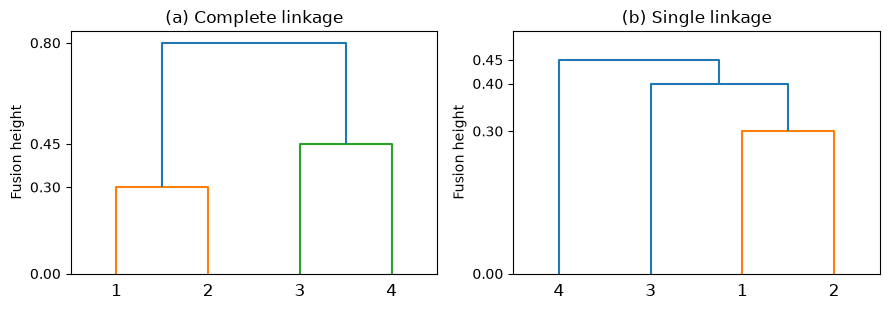

In [15]:
# each row: [group A, group B, fusion height, size of new group]
Z_complete = np.array([[0, 1, 0.30, 2],    # {1,2}       -> group 4
                       [2, 3, 0.45, 2],    # {3,4}       -> group 5
                       [4, 5, 0.80, 4]])   # {1,2,3,4}
Z_single = np.array([[0, 1, 0.30, 2],      # {1,2}       -> group 4
                     [2, 4, 0.40, 3],      # {1,2,3}     -> group 5
                     [3, 5, 0.45, 4]])     # {1,2,3,4}
obs_names = ['1', '2', '3', '4']

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
dendrogram(Z_complete, labels=obs_names, ax=axes[0])
axes[0].set_title('(a) Complete linkage')
axes[0].set_ylabel('Fusion height')
axes[0].set_yticks([0, 0.30, 0.45, 0.80])
dendrogram(Z_single, labels=obs_names, ax=axes[1])
axes[1].set_title('(b) Single linkage')
axes[1].set_ylabel('Fusion height')
axes[1].set_yticks([0, 0.30, 0.40, 0.45])
axes[1].set_ylim(0, 0.51)
plt.tight_layout()
plt.show()

**(c)** Cutting the complete-linkage tree at 0.60 gives {1, 2} and {3, 4}.

**(d)** Cutting the single-linkage tree at 0.42 gives {1, 2, 3} and {4}.

**(e)** I swap the branches at each merge in the complete-linkage tree. The leaves now read 4, 3, 2, 1, with the same groups and merge heights.

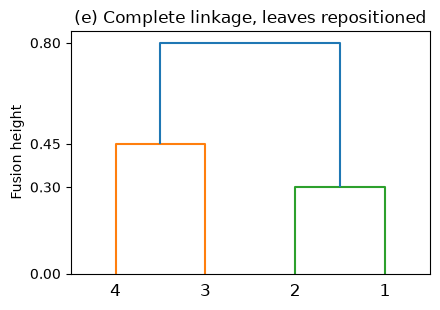

In [16]:
# same fusions as (a), but the two branches are swapped at every fusion
Z_swapped = np.array([[1, 0, 0.30, 2],
                      [3, 2, 0.45, 2],
                      [5, 4, 0.80, 4]])
plt.figure(figsize=(4.5, 3.2))
dendrogram(Z_swapped, labels=obs_names)
plt.title('(e) Complete linkage, leaves repositioned')
plt.ylabel('Fusion height')
plt.yticks([0, 0.30, 0.45, 0.80])
plt.tight_layout()
plt.show()